[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PARODBE/UAX_Fundamento_Ciencia_de_Datos/blob/main/Notebooks/Fase_4_Conglomerados.ipynb)

# Capítulo 4. Análisis de conglomerados

En esta fase retiro los extremos definidos con límites calculados en train y agrupo los compuestos restantes a partir de los 217 descriptores moleculares calculados con RDKit. Incluyo MolLogP entre los descriptores y excluyo LipinskiViolations porque es una variable derivada. Tras retirar los descriptores constantes, ajusto la imputación y la estandarización con train, reduzco la matriz a las dos primeras componentes principales y aplico K-means sobre ellas. Después describo los grupos y reviso su composición DILI; la etiqueta no se utiliza para formar los conglomerados.

In [6]:
# Instalo RDKit para dibujar las estructuras de los compuestos representativos.
%pip -q install rdkit


## 4.1. Lectura de los datos

Cargo las particiones publicadas para no tener que subir archivos a Colab. Aplico a train los límites de 1,5 × RIC calculados solo con esa partición; el análisis se realiza con los compuestos restantes de train.


In [7]:
# Cargo las librerías para leer y analizar las tablas.
from pathlib import Path  # Organizo las rutas locales.
import pandas as pd  # Leo y preparo tablas.
import numpy as np  # Calculo estadísticas numéricas.
from IPython.display import display  # Muestro resultados en Colab.

# Defino una carpeta local para guardar copias de trabajo.
DATA_DIR = Path('/content/datos_dili')  # Uso la carpeta de Colab.
DATA_DIR.mkdir(parents=True, exist_ok=True)  # Creo la carpeta si hace falta.

# Indico la carpeta pública con los datos que preparé en la fase 2.
BASE_URL = 'https://raw.githubusercontent.com/PARODBE/UAX_Fundamento_Ciencia_de_Datos/main/Data/'  # Defino el enlace base.
dilist_original = pd.read_csv(BASE_URL + 'DILIst_FDA.csv')  # Cargo la fuente original.
estructuras = pd.read_csv(BASE_URL + 'estructuras_nombres.csv')  # Cargo el mapa de nombres y estructuras.
datos_limpios = pd.read_csv(BASE_URL + 'dilist_descriptores.csv')  # Cargo los compuestos con todos los descriptores.
train_df = pd.read_csv(BASE_URL + 'dilist_train.csv')  # Cargo entrenamiento.
test_df = pd.read_csv(BASE_URL + 'dilist_test.csv')  # Cargo prueba.

# Creo una tabla completa para revisar cobertura y calidad de estructuras.
dilist = dilist_original.rename(columns={'DILIst_Classification': 'DILI'}).copy()  # Renombro la clase.
datos = dilist.merge(estructuras, on='CompoundName', how='left')  # Uno las etiquetas con el estado de búsqueda.
claves_con_etiqueta = datos.dropna(subset=['InChIKey']).groupby('InChIKey')['DILI'].nunique()  # Cuento clases por estructura.
claves_conflictivas = claves_con_etiqueta[claves_con_etiqueta > 1].index  # Identifico etiquetas contradictorias.
datos_conflicto = datos[datos['InChIKey'].isin(claves_conflictivas)].copy()  # Guardo los registros conflictivos.

# Identifico todos los descriptores numéricos salvo etiquetas e identificadores.
columnas_excluir = ['DILI', 'DILIST_ID', 'InChIKey', 'CID', 'SMILES', 'CompoundName', 'Routes_of_Administration', 'chembl_id']  # Evito datos no moleculares.
DESCRIPTORES = [columna for columna in datos_limpios.select_dtypes(include='number').columns if columna not in columnas_excluir]  # Selecciono propiedades moleculares.

# Guardo copias locales de las tablas de trabajo.
for nombre, tabla in [('dilist_descriptores.csv', datos_limpios), ('dilist_train.csv', train_df), ('dilist_test.csv', test_df)]:  # Recorro las tablas.
    tabla.to_csv(DATA_DIR / nombre, index=False)  # Guardo una copia en Colab.
print('He cargado los datos del repositorio:', DATA_DIR)  # Confirmo la ruta local.
print('Descriptores numéricos disponibles:', len(DESCRIPTORES))  # Muestro el catálogo disponible.

# Defino las cinco propiedades usadas para marcar observaciones extremas.
variables_filtro = ['MolWt', 'MolLogP', 'NumHDonors', 'NumHAcceptors', 'TPSA']  # Uso las propiedades del EDA.
variables_filtro = [v for v in variables_filtro if v in train_df.columns]  # Compruebo que existan.
train_original = train_df.copy()  # Guardo train antes del filtro.
test_original = test_df.copy()  # Guardo test antes del filtro.

# Calculo los límites de 1,5 × RIC únicamente con train.
q1 = train_original[variables_filtro].quantile(0.25)  # Calculo el primer cuartil.
q3 = train_original[variables_filtro].quantile(0.75)  # Calculo el tercer cuartil.
ric = q3 - q1  # Calculo el rango intercuartílico.
limite_inferior = q1 - 1.5 * ric  # Defino los límites inferiores.
limite_superior = q3 + 1.5 * ric  # Defino los límites superiores.
fuera_train = (train_original[variables_filtro].lt(limite_inferior) | train_original[variables_filtro].gt(limite_superior)).any(axis=1)  # Marco extremos de train.
fuera_test = (test_original[variables_filtro].lt(limite_inferior) | test_original[variables_filtro].gt(limite_superior)).any(axis=1)  # Aplico los mismos límites a test.
train_df = train_original.loc[~fuera_train].reset_index(drop=True)  # Retiro extremos de train.
test_df = test_original.loc[~fuera_test].reset_index(drop=True)  # Retiro extremos de test.
print(f"Filtro 1,5 × RIC: train {len(train_df)}/{len(train_original)}; test {len(test_df)}/{len(test_original)} compuestos.")  # Informo los tamaños.
print('Clases en train:', train_df['DILI'].value_counts().sort_index().to_dict())  # Compruebo train.
print('Clases en test:', test_df['DILI'].value_counts().sort_index().to_dict())  # Compruebo test.
print('Límites calculados en train:', {v: (round(limite_inferior[v], 2), round(limite_superior[v], 2)) for v in variables_filtro})  # Muestro los umbrales.

He cargado los datos del repositorio: /content/datos_dili
Descriptores numéricos disponibles: 218
Filtro 1,5 × RIC: train 832/947; test 201/237 compuestos.
Clases en train: {0: 307, 1: 525}
Clases en test: {0: 68, 1: 133}
Límites calculados en train: {'MolWt': (np.float64(-1.01), np.float64(687.9)), 'MolLogP': (np.float64(-3.82), np.float64(8.22)), 'NumHDonors': (np.float64(-2.0), np.float64(6.0)), 'NumHAcceptors': (np.float64(-1.5), np.float64(10.5)), 'TPSA': (np.float64(-59.66), np.float64(220.06))}


## 4.2. Imputación, estandarización, PCA y selección de k

Utilizo los 217 descriptores moleculares escalares de RDKit, incluido MolLogP, y excluyo LipinskiViolations, que se calcula a partir de otros descriptores. Los descriptores constantes en train se retiran porque no aportan variación. Los valores ausentes se imputan con la mediana y las variables se estandarizan; ambos pasos se ajustan con train. A continuación, la PCA resume todos los descriptores en dos componentes y K-means se aplica sobre PC1 y PC2. Comparo valores de k entre 2 y 6 con WCSS y silhouette. La proporción de variación explicada por las dos componentes permite valorar cuánta información resume esta proyección.

Descriptores RDKit iniciales: 217
Descriptores variables para el análisis: 210
Varianza explicada por componente:


,porcentaje
PC1,16.5
PC2,7.6


Las dos componentes explican 24.1% de la variación de los descriptores.


,k,WCSS,silhouette
0,2,23717.131,0.394
1,3,16983.825,0.394
2,4,13237.400,0.339
3,5,10803.322,0.341
4,6,8863.330,0.351


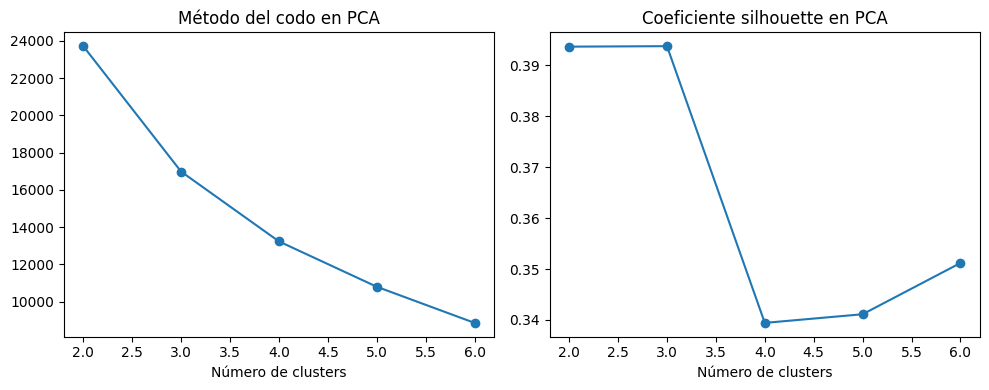

In [8]:
# Limito el aviso de detección de núcleos de joblib en Colab.
import os  # Configuro el entorno de ejecución.
os.environ['LOKY_MAX_CPU_COUNT'] = '2'  # Indico un número seguro de núcleos para joblib.

# Importo las herramientas para imputar, escalar, reducir dimensiones y agrupar.
import matplotlib.pyplot as plt  # Dibujo las métricas de clustering.
from sklearn.impute import SimpleImputer  # Completo posibles valores ausentes.
from sklearn.preprocessing import StandardScaler  # Pongo los descriptores en escalas comparables.
from sklearn.decomposition import PCA  # Reduzco los descriptores a dos componentes.
from sklearn.cluster import KMeans  # Agrupo los compuestos.
from sklearn.metrics import silhouette_score  # Evalúo cohesión y separación de los grupos.

# Excluyo la variable derivada y conservo los descriptores moleculares de RDKit.
descriptores_rdkit = [variable for variable in DESCRIPTORES if variable != 'LipinskiViolations']  # Quito la variable derivada.
variables_cluster = [variable for variable in descriptores_rdkit if train_df[variable].nunique(dropna=True) > 1]  # Retiro descriptores constantes en train.
print('Descriptores RDKit iniciales:', len(descriptores_rdkit))  # Muestro cuántos descriptores utilizo.
print('Descriptores variables para el análisis:', len(variables_cluster))  # Muestro cuántos quedan tras retirar constantes.

# Ajusto la imputación y la estandarización únicamente con train.
imputador = SimpleImputer(strategy='median')  # Defino la imputación por mediana.
X_imputado = imputador.fit_transform(train_df[variables_cluster])  # Aprendo las medianas y las aplico a train.
escalador = StandardScaler()  # Defino la estandarización.
X_estandar = escalador.fit_transform(X_imputado)  # Aprendo medias y desviaciones en train y estandarizo.

# Ajusto PCA con todos los descriptores y conservo las dos primeras componentes.
pca = PCA(n_components=2)  # Defino una proyección bidimensional.
X_pca = pca.fit_transform(X_estandar)  # Ajusto PCA y proyecto train.
varianza_pca = pd.Series(pca.explained_variance_ratio_, index=['PC1', 'PC2'])  # Calculo la varianza explicada.
print('Varianza explicada por componente:')  # Presento la información conservada.
display((100 * varianza_pca).round(1).to_frame('porcentaje'))  # Muestro el porcentaje de cada componente.
print(f'Las dos componentes explican {100 * pca.explained_variance_ratio_.sum():.1f}% de la variación de los descriptores.')  # Resumo la proyección.

# Comparo entre dos y seis grupos usando PC1 y PC2.
resultados = []  # Guardo las métricas de cada valor de k.
for k in range(2, 7):  # Pruebo los valores solicitados.
    ajuste = KMeans(n_clusters=k, random_state=42, n_init=20)  # Defino un modelo reproducible.
    etiquetas = ajuste.fit_predict(X_pca)  # Ajusto K-means sobre las dos componentes.
    resultados.append({'k': k, 'WCSS': ajuste.inertia_, 'silhouette': silhouette_score(X_pca, etiquetas)})  # Guardo las métricas.
tabla_k = pd.DataFrame(resultados)  # Organizo los resultados.
display(tabla_k.round(3))  # Muestro WCSS y silhouette.

# Dibujo el método del codo y el coeficiente silhouette.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # Creo dos paneles.
axes[0].plot(tabla_k['k'], tabla_k['WCSS'], marker='o')  # Represento WCSS.
axes[0].set_title('Método del codo en PCA')  # Titulo el primer panel.
axes[0].set_xlabel('Número de clusters')  # Etiqueto el eje horizontal.
axes[1].plot(tabla_k['k'], tabla_k['silhouette'], marker='o')  # Represento silhouette.
axes[1].set_title('Coeficiente silhouette en PCA')  # Titulo el segundo panel.
axes[1].set_xlabel('Número de clusters')  # Etiqueto el eje horizontal.
plt.tight_layout()  # Ajusto los paneles.
plt.show()  # Muestro las gráficas.

## 4.3. Visualización de los grupos en PCA

Selecciono el valor de k con mayor silhouette y ajusto K-means sobre las dos primeras componentes principales calculadas a partir de los descriptores moleculares. Muestro la proyección coloreada por conglomerado y, por separado, por etiqueta DILI. La etiqueta se incorpora únicamente después de formar los grupos, para describir su composición.

Número de clusters elegido: 3
Elijo k = 3 por obtener la silhouette más alta entre los valores probados (0.394).


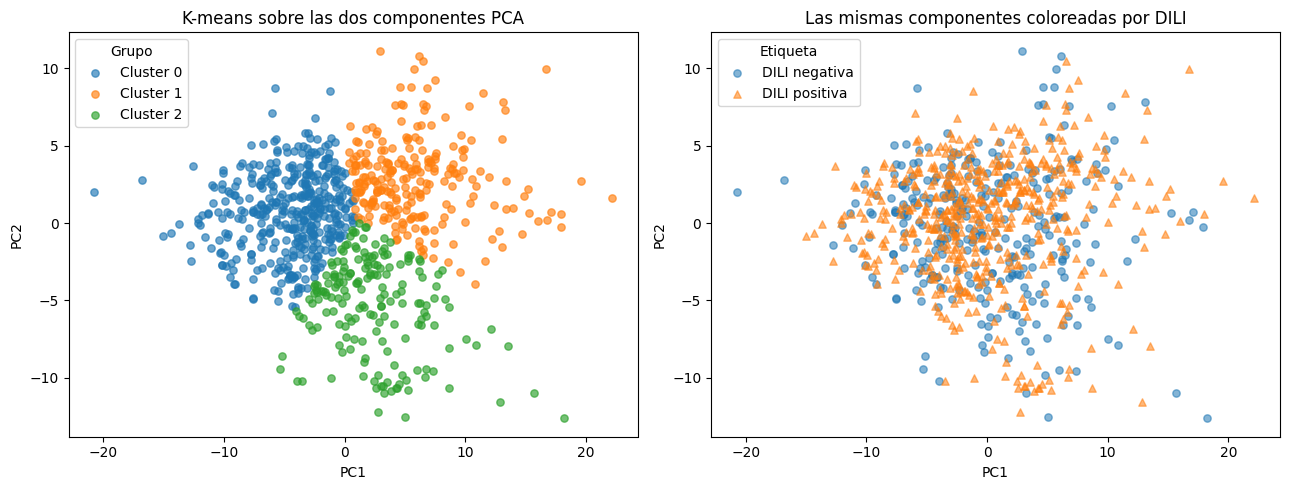

In [9]:
# Elijo k según el coeficiente silhouette y ajusto K-means sobre PC1 y PC2.
k_final = int(tabla_k.loc[tabla_k['silhouette'].idxmax(), 'k'])  # Selecciono el k con mayor silhouette.
modelo_cluster = KMeans(n_clusters=k_final, random_state=42, n_init=20)  # Creo el modelo final.
clusters_train = modelo_cluster.fit_predict(X_pca)  # Ajusto K-means en las dos componentes.
print('Número de clusters elegido:', k_final)  # Informo el número de grupos.
mejor_silueta = tabla_k.loc[tabla_k['k'] == k_final, 'silhouette'].iloc[0]  # Recupero la silhouette elegida.
print(f'Elijo k = {k_final} por obtener la silhouette más alta entre los valores probados ({mejor_silueta:.3f}).')  # Justifico la elección.

# Añado el grupo y las coordenadas PCA a los registros de train.
train_cluster = train_df.copy()  # Conservo los datos originales.
train_cluster['cluster'] = clusters_train  # Añado la asignación de grupo.
train_cluster['PC1'] = X_pca[:, 0]  # Añado la primera componente.
train_cluster['PC2'] = X_pca[:, 1]  # Añado la segunda componente.

# Comparo la proyección por cluster y por etiqueta DILI.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))  # Creo dos paneles.
for cluster in sorted(train_cluster['cluster'].unique()):  # Recorro los grupos.
    parte = train_cluster[train_cluster['cluster'] == cluster]  # Selecciono un grupo.
    axes[0].scatter(parte['PC1'], parte['PC2'], alpha=0.65, s=28, label=f'Cluster {cluster}')  # Dibujo sus compuestos.
axes[0].set_title('K-means sobre las dos componentes PCA')  # Titulo el primer panel.
axes[0].set_xlabel('PC1')  # Etiqueto el eje horizontal.
axes[0].set_ylabel('PC2')  # Etiqueto el eje vertical.
axes[0].legend(title='Grupo')  # Añado la leyenda.
for clase, nombre, marcador in [(0, 'DILI negativa', 'o'), (1, 'DILI positiva', '^')]:  # Recorro las clases solo para visualizar.
    parte = train_cluster[train_cluster['DILI'] == clase]  # Selecciono una clase.
    axes[1].scatter(parte['PC1'], parte['PC2'], alpha=0.55, s=28, marker=marcador, label=nombre)  # Dibujo sus compuestos.
axes[1].set_title('Las mismas componentes coloreadas por DILI')  # Titulo el segundo panel.
axes[1].set_xlabel('PC1')  # Etiqueto el eje horizontal.
axes[1].set_ylabel('PC2')  # Etiqueto el eje vertical.
axes[1].legend(title='Etiqueta')  # Añado la leyenda.
plt.tight_layout()  # Ajusto la figura.
plt.show()  # Muestro la proyección.

## 4.4. Perfil de los conglomerados y ejemplos

Comparo el tamaño de los grupos, la proporción de etiquetas DILI positivas y sus medias en descriptores. Para resumir los 217 descriptores, identifico los diez cuya media estandarizada más varía entre grupos. La etiqueta se utiliza solo después de asignar los conglomerados. También muestro hasta tres compuestos positivos próximos al centro del grupo con mayor proporción DILI positiva.

,n,positivos,porcentaje_DILI_positiva,diferencia_pp_vs_train
cluster,,,,
1,240,165,68.8,5.6
0,408,256,62.7,-0.4
2,184,104,56.5,-6.6


Diez descriptores con mayor diferencia estandarizada entre grupos:


cluster,0,1,2,rango entre grupos (DE)
Chi0,-0.73,1.06,0.23,1.78
HeavyAtomCount,-0.74,1.04,0.29,1.78
NumHeteroatoms,-0.29,1.05,-0.73,1.78
NumValenceElectrons,-0.74,1.03,0.31,1.77
HeavyAtomMolWt,-0.69,1.07,0.13,1.76
ExactMolWt,-0.71,1.06,0.19,1.76
Chi1,-0.74,1.02,0.32,1.76
MolWt,-0.70,1.06,0.19,1.76
LabuteASA,-0.74,1.01,0.33,1.75
Chi4n,-0.73,0.47,1.01,1.74


El cluster 1 tiene 68.8% de DILI positivos.
La proporción positiva general de train es 63.1%.
La etiqueta describe la composición de DILIst y no el riesgo clínico de los fármacos.


,CompoundName,InChIKey,DILI,distancia_al_centro
249,meropenem,DMJNNHOOLUXYBV-PQTSNVLCSA-N,1,0.358
16,Eltrombopag,SVOQIEJWJCQGDQ-UHFFFAOYSA-N,1,0.479
713,oxacillin,UWYHMGVUTGAWSP-JKIFEVAISA-N,1,0.562


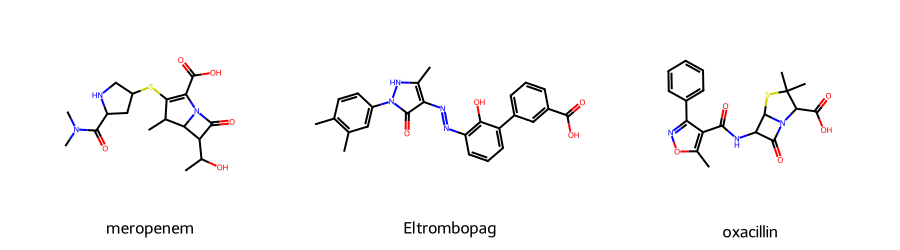

In [10]:
# Resumo el tamaño y la proporción DILI positiva de cada grupo.
perfil_dili = train_cluster.groupby('cluster').agg(n=('DILI', 'size'), positivos=('DILI', 'sum'), proporcion_DILI_positiva=('DILI', 'mean'))  # Cuento y resumo las etiquetas.
perfil_dili['porcentaje_DILI_positiva'] = (100 * perfil_dili['proporcion_DILI_positiva']).round(1)  # Expreso el porcentaje positivo.
prevalencia_train = train_cluster['DILI'].mean()  # Calculo la proporción positiva general.
perfil_dili['diferencia_pp_vs_train'] = (100 * (perfil_dili['proporcion_DILI_positiva'] - prevalencia_train)).round(1)  # Comparo grupos con train.
display(perfil_dili.drop(columns='proporcion_DILI_positiva').sort_values('porcentaje_DILI_positiva', ascending=False))  # Muestro el perfil DILI.

# Calculo la media de cada descriptor estandarizado dentro de cada grupo.
datos_z = pd.DataFrame(X_estandar, columns=variables_cluster, index=train_cluster.index)  # Organizo los descriptores escalados.
datos_z['cluster'] = train_cluster['cluster']  # Añado la etiqueta de conglomerado.
medias_z = datos_z.groupby('cluster').mean()  # Calculo medias estandarizadas por grupo.
rango_z = medias_z.max(axis=0) - medias_z.min(axis=0)  # Mido cuánto varía cada descriptor entre grupos.
descriptores_perfil = rango_z.sort_values(ascending=False).head(10).index.tolist()  # Selecciono los diez más diferenciadores.
tabla_perfiles = medias_z[descriptores_perfil].T  # Organizo los diez descriptores en filas.
tabla_perfiles['rango entre grupos (DE)'] = rango_z[descriptores_perfil]  # Añado la diferencia estandarizada.
print('Diez descriptores con mayor diferencia estandarizada entre grupos:')  # Explico la tabla.
display(tabla_perfiles.round(2))  # Muestro medias en unidades de desviación estándar.

# Selecciono el grupo con mayor proporción DILI positiva para describir sus ejemplos.
cluster_mas_positivo = int(perfil_dili['proporcion_DILI_positiva'].idxmax())  # Identifico el grupo con más positivos.
print(f'El cluster {cluster_mas_positivo} tiene {perfil_dili.loc[cluster_mas_positivo, "porcentaje_DILI_positiva"]:.1f}% de DILI positivos.')  # Muestro su proporción.
print(f'La proporción positiva general de train es {100 * prevalencia_train:.1f}%.')  # Añado la referencia global.
print('La etiqueta describe la composición de DILIst y no el riesgo clínico de los fármacos.')  # Delimito la interpretación.

# Busco compuestos positivos próximos al centro de su grupo en PCA.
positivos_grupo = train_cluster[(train_cluster['cluster'] == cluster_mas_positivo) & (train_cluster['DILI'] == 1)].copy()  # Selecciono positivos.
centro = modelo_cluster.cluster_centers_[cluster_mas_positivo]  # Tomo el centro del grupo en el plano PCA.
positivos_grupo['distancia_al_centro'] = np.sqrt((positivos_grupo['PC1'] - centro[0]) ** 2 + (positivos_grupo['PC2'] - centro[1]) ** 2)  # Calculo distancias.
ejemplos = positivos_grupo.sort_values('distancia_al_centro').head(3)  # Selecciono hasta tres ejemplos.
display(ejemplos[['CompoundName', 'InChIKey', 'DILI', 'distancia_al_centro']].round(3))  # Muestro identificadores.

# Dibujo las estructuras químicas de los ejemplos con RDKit.
from rdkit import Chem  # Leo estructuras desde SMILES.
from rdkit.Chem import Draw  # Dibujo las moléculas.
moleculas = []  # Guardo moléculas válidas.
leyendas = []  # Guardo los nombres.
for _, fila in ejemplos.iterrows():  # Recorro los ejemplos.
    molecula = Chem.MolFromSmiles(fila['SMILES'])  # Creo la molécula desde SMILES.
    if molecula is not None:  # Compruebo que sea válida.
        moleculas.append(molecula)  # Guardo la estructura.
        leyendas.append(str(fila['CompoundName']))  # Guardo la leyenda.
if moleculas:  # Compruebo que haya moléculas.
    display(Draw.MolsToGridImage(moleculas, molsPerRow=3, subImgSize=(300, 250), legends=leyendas))  # Muestro las estructuras.

## Interpretación de los resultados

Tras aplicar a train el filtro de 1,5 × RIC calculado con las cinco propiedades fisicoquímicas, quedaron 832 de los 947 compuestos. Para formar los grupos se utilizaron 217 descriptores RDKit, incluido MolLogP; se excluyó LipinskiViolations por ser una variable derivada y se retiraron siete descriptores constantes. Los 210 descriptores restantes se imputaron por la mediana y se estandarizaron con parámetros aprendidos en train.

Las dos primeras componentes principales explican el 24,1 % de la variación total (16,5 % PC1 y 7,6 % PC2). Esta proporción indica que la figura bidimensional ofrece una síntesis limitada del espacio químico: facilita visualizar los grupos, pero deja fuera la mayor parte de la variabilidad. K-means se ajustó sobre esas dos componentes, no directamente sobre las 210 columnas.

Entre k = 2 y k = 6, la silhouette más alta se obtuvo con k = 3 (0,394), aunque el resultado para k = 2 fue prácticamente igual (0,394; 0,39365 frente a 0,39374). Por el criterio programado se seleccionaron tres grupos, pero la diferencia es demasiado pequeña para afirmar que exista una separación claramente superior. El WCSS disminuye al aumentar k, como cabe esperar, y no muestra por sí solo un codo inequívoco.

El conglomerado 0 reúne 408 compuestos y presenta un 62,7 % de clasificaciones DILI positivas, prácticamente igual al 63,1 % global de train. El conglomerado 1 contiene 240 compuestos y alcanza el porcentaje positivo más alto (68,8 %, 5,6 puntos porcentuales por encima de train). El conglomerado 2 incluye 184 compuestos y registra el porcentaje más bajo (56,5 %, 6,6 puntos por debajo). Las diferencias sugieren variaciones moderadas en la composición de las etiquetas, no una separación nítida entre compuestos positivos y negativos.

Los perfiles estandarizados ayudan a caracterizar químicamente los grupos. El conglomerado 1 presenta medias superiores a la media de train en descriptores de tamaño y complejidad, como MolWt, HeavyAtomCount, NumHeteroatoms y NumValenceElectrons. El conglomerado 0 queda por debajo de la media en varios descriptores de tamaño; el conglomerado 2 destaca por un valor bajo de NumHeteroatoms y alto de Chi4n. El mayor porcentaje DILI positivo del grupo 1 podría motivar una revisión de la relación entre tamaño, composición atómica y etiqueta en este conjunto, pero no demuestra que esas propiedades causen toxicidad. Además, DILI se utilizó únicamente después de formar los grupos y representa la clasificación de DILIst, no una estimación de riesgo clínico individual.

Los compuestos representativos y sus estructuras sirven para ilustrar el perfil del conglomerado con mayor proporción positiva. Se seleccionaron por cercanía al centro en el plano PCA, por lo que son ejemplos centrales del grupo y no los casos más tóxicos ni necesariamente los más representativos en el espacio completo de 210 descriptores.